In [1]:
# loading modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import colorcet as cc

In [2]:
# loading dhe data
Brain = pd.read_csv("/content/20_02_2026_Includes_reptiles.csv")
# Brain = Brain.drop(['Unnamed: 0'], axis=1)
Brain.head(8)

,Animal,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m,Unnamed: 8,notes
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,for mammals and birds forebrain includes palli...
1,Algerian Sand Gecko,0.0055,0.0002,0.01,"740,000","151,000","1,771,000",0.99,NaN,NaN
2,Brown Anole,0.0110,0.0013,0.03,"898,000","648,000","2,792,000",3.44,NaN,NaN
3,Peters' Eyelid Skink,0.0153,0.0003,0.03,"1,525,000","120,000","3,049,000",6.43,NaN,NaN
4,Hispaniolan Curlytail Lizard,0.0357,0.0039,0.11,"1,528,000","2,216,000","7,063,000",22.47,NaN,NaN
5,Asian Grass Lizard,0.0122,0.0007,0.03,"1,528,000","531,000","4,021,000",3.59,NaN,NaN
6,Sumatran Flying Dragon,0.0196,0.0017,0.04,"1,539,000","1,296,000","5,174,000",2.60,NaN,NaN
7,Sand Lizard,0.0422,0.0020,0.09,"1,749,000","428,000","4,341,000",16.00,NaN,NaN


In [3]:
# Dropping NaN values
Brain = Brain.drop('notes', axis=1)
Brain = Brain.drop('Unnamed: 8', axis=1)
Brain = Brain.dropna().reset_index(drop=True)

# Data preparation and feature engineering

In [4]:
# Converting into float and removing commas
if Brain['Forebrain n'].dtype != 'float64':
     Brain['Forebrain n'] = Brain['Forebrain n'].str.replace(',', '').astype(float)
if Brain['Cerebellum n'].dtype != 'float64':
     Brain['Cerebellum n'] = Brain['Cerebellum n'].str.replace(',', '').astype(float)
if Brain['Whole brain n'].dtype != 'float64':
     Brain['Whole brain n'] = Brain['Whole brain n'].str.replace(',', '').astype(float)

In [5]:
Brain['Cerebellum n / Forebrain n'] = Brain['Cerebellum n'] / Brain['Forebrain n']

In [6]:
# Getting relative cortical and cerebellar masses and relative number of neurons in each structure
Brain['Forebrain m r %'] = Brain['Forebrain m']/Brain['Whole brain m']*100
Brain['Cerebellum m r %'] = Brain['Cerebellum m']/Brain['Whole brain m']*100
Brain['Forebrain n r %'] = Brain['Forebrain n']/Brain['Whole brain n']*100
Brain['Cerebellum n r %'] = Brain['Cerebellum n']/Brain['Whole brain n']*100

In [7]:
# Getting neuron densities in a miligram of structure
Brain['Forebrain n d'] = Brain['Forebrain n']/(Brain['Forebrain m']*1000)
Brain['Cerebellum n d'] = Brain['Cerebellum n']/(Brain['Cerebellum m']*1000)
Brain['Whole brain n d'] = Brain['Whole brain n']/(Brain['Whole brain m']*1000)

In [8]:
# Brain mass per body mass
Brain['Forebrain m per body m'] = Brain['Forebrain m']/Brain['Body m']*100
Brain['Cerebellum m per body m'] = Brain['Cerebellum m']/Brain['Body m']*100
Brain['Whole brain m per body m'] = Brain['Whole brain m']/Brain['Body m']*100

In [9]:
# Number of neurons per body mass
Brain['Forebrain n per body m'] = Brain['Forebrain n']/Brain['Body m']
Brain['Cerebellum n per body m'] = Brain['Cerebellum n']/Brain['Body m']
Brain['Whole brain n per body m'] = Brain['Whole brain n']/Brain['Body m']

In [10]:
# Cortex/rest of brain and cerebellum/rest of brain
Brain['Forebrain m/Rest m'] = Brain['Forebrain m']/(Brain['Whole brain m']-Brain['Forebrain m']-Brain['Cerebellum m'])
Brain['Cerebellum m/Rest m'] = Brain['Cerebellum m']/(Brain['Whole brain m']-Brain['Forebrain m']-Brain['Cerebellum m'])
Brain['Forebrain m/Cerebellum m'] = Brain['Forebrain m']/Brain['Cerebellum m']

In [11]:
Breng = Brain
Breng.head()

,Animal,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m,Cerebellum n / Forebrain n,Forebrain m r %,...,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m,Forebrain m/Rest m,Cerebellum m/Rest m,Forebrain m/Cerebellum m
0,Algerian Sand Gecko,0.0055,0.0002,0.01,740000.0,151000.0,1771000.0,0.99,0.204054,55.000000,...,177100.000000,0.555556,0.020202,1.010101,747474.747475,152525.252525,1.788889e+06,1.279070,0.046512,27.500000
1,Brown Anole,0.0110,0.0013,0.03,898000.0,648000.0,2792000.0,3.44,0.721604,36.666667,...,93066.666667,0.319767,0.037791,0.872093,261046.511628,188372.093023,8.116279e+05,0.621469,0.073446,8.461538
2,Peters' Eyelid Skink,0.0153,0.0003,0.03,1525000.0,120000.0,3049000.0,6.43,0.078689,51.000000,...,101633.333333,0.237947,0.004666,0.466563,237169.517885,18662.519440,4.741835e+05,1.062500,0.020833,51.000000
3,Hispaniolan Curlytail Lizard,0.0357,0.0039,0.11,1528000.0,2216000.0,7063000.0,22.47,1.450262,32.454545,...,64209.090909,0.158879,0.017356,0.489542,68001.780151,98620.382733,3.143302e+05,0.507102,0.055398,9.153846
4,Asian Grass Lizard,0.0122,0.0007,0.03,1528000.0,531000.0,4021000.0,3.59,0.347513,40.666667,...,134033.333333,0.339833,0.019499,0.835655,425626.740947,147910.863510,1.120056e+06,0.713450,0.040936,17.428571


In [12]:
pd.set_option('display.max_columns', None)
Breng.describe()

,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m,Cerebellum n / Forebrain n,Forebrain m r %,Cerebellum m r %,Forebrain n r %,Cerebellum n r %,Forebrain n d,Cerebellum n d,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m,Forebrain m/Rest m,Cerebellum m/Rest m,Forebrain m/Cerebellum m
count,330.000000,330.000000,330.000000,3.300000e+02,3.300000e+02,3.300000e+02,3.300000e+02,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,3.300000e+02,330.000000,330.000000,330.000000,330.000000,3.300000e+02,3.300000e+02,3.300000e+02,330.000000,330.000000,330.000000
mean,34.217430,8.247851,49.282521,3.238109e+08,1.975296e+09,2.352337e+09,5.232533e+04,2.385756,55.960053,9.618203,35.903580,45.813305,65348.665261,4.494415e+05,100491.777439,0.564243,0.112360,1.000523,6.200980e+05,7.418808e+05,1.587625e+06,2.016078,0.335795,12.086050
std,229.123587,72.086208,336.614966,1.206654e+09,1.592512e+10,1.678187e+10,5.055613e+05,3.810317,11.771059,5.426022,17.187178,25.454554,55583.643073,2.452672e+05,67693.740223,0.659891,0.138413,1.088195,1.257084e+06,1.260075e+06,2.803042e+06,1.374047,0.255364,18.934230
min,0.005500,0.000100,0.010000,7.400000e+05,3.800000e+04,1.771000e+06,9.900000e-01,0.019388,22.352941,0.270270,2.175926,1.023431,1130.495495,7.379310e+04,14033.562823,0.003764,0.000049,0.005378,4.178632e+02,3.596639e+01,1.137692e+03,0.355140,0.006494,1.291667
25%,0.208950,0.013900,0.370000,7.458000e+06,3.296500e+06,1.679150e+07,7.367750e+01,0.467534,47.829506,4.312569,20.709013,22.764272,28261.952959,2.520006e+05,47082.638889,0.133708,0.012169,0.246130,3.327189e+04,2.783603e+04,1.140064e+05,1.193045,0.103356,3.819468
50%,0.874500,0.211800,1.759000,4.781150e+07,1.242200e+08,2.102750e+08,3.002000e+02,1.303980,56.510870,10.502380,34.895425,48.937947,49177.912114,4.208729e+05,83399.540914,0.315479,0.064836,0.620352,1.405840e+05,2.400610e+05,4.946791e+05,1.687753,0.351503,6.003177
75%,3.850500,0.786250,6.608500,2.584875e+08,3.612775e+08,7.528975e+08,1.324000e+03,3.211467,64.067308,13.842634,49.979599,69.049850,79021.842130,5.742381e+05,134983.607184,0.734128,0.163546,1.341115,4.627573e+05,8.741723e+05,1.823472e+06,2.388190,0.432519,11.639601
max,2847.000000,1171.000000,4618.000000,1.634000e+10,2.507000e+11,2.570400e+11,7.500000e+06,44.823887,84.888889,28.685259,76.491228,97.533458,363636.363636,1.650000e+06,459030.812325,3.288690,0.714286,6.375000,1.142857e+07,1.178571e+07,2.926321e+07,10.100016,1.951667,215.000000


In [13]:
Breng.shape

(330, 25)

In [14]:
pd.set_option('display.max_rows', 400, 'display.max_columns', 50)
Breng.head(400)

,Animal,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m,Cerebellum n / Forebrain n,Forebrain m r %,Cerebellum m r %,Forebrain n r %,Cerebellum n r %,Forebrain n d,Cerebellum n d,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m,Forebrain m/Rest m,Cerebellum m/Rest m,Forebrain m/Cerebellum m
0,Algerian Sand Gecko,0.00550,0.0002,0.010,7.400000e+05,1.510000e+05,1.771000e+06,0.990,0.204054,55.000000,2.000000,41.784303,8.526256,134545.454545,7.550000e+05,177100.000000,0.555556,0.020202,1.010101,7.474747e+05,1.525253e+05,1.788889e+06,1.279070,0.046512,27.500000
1,Brown Anole,0.01100,0.0013,0.030,8.980000e+05,6.480000e+05,2.792000e+06,3.440,0.721604,36.666667,4.333333,32.163324,23.209169,81636.363636,4.984615e+05,93066.666667,0.319767,0.037791,0.872093,2.610465e+05,1.883721e+05,8.116279e+05,0.621469,0.073446,8.461538
2,Peters' Eyelid Skink,0.01530,0.0003,0.030,1.525000e+06,1.200000e+05,3.049000e+06,6.430,0.078689,51.000000,1.000000,50.016399,3.935717,99673.202614,4.000000e+05,101633.333333,0.237947,0.004666,0.466563,2.371695e+05,1.866252e+04,4.741835e+05,1.062500,0.020833,51.000000
3,Hispaniolan Curlytail Lizard,0.03570,0.0039,0.110,1.528000e+06,2.216000e+06,7.063000e+06,22.470,1.450262,32.454545,3.545455,21.633867,31.374770,42801.120448,5.682051e+05,64209.090909,0.158879,0.017356,0.489542,6.800178e+04,9.862038e+04,3.143302e+05,0.507102,0.055398,9.153846
4,Asian Grass Lizard,0.01220,0.0007,0.030,1.528000e+06,5.310000e+05,4.021000e+06,3.590,0.347513,40.666667,2.333333,38.000497,13.205670,125245.901639,7.585714e+05,134033.333333,0.339833,0.019499,0.835655,4.256267e+05,1.479109e+05,1.120056e+06,0.713450,0.040936,17.428571
5,Sumatran Flying Dragon,0.01960,0.0017,0.040,1.539000e+06,1.296000e+06,5.174000e+06,2.600,0.842105,49.000000,4.250000,29.744878,25.048319,78520.408163,7.623529e+05,129350.000000,0.753846,0.065385,1.538462,5.919231e+05,4.984615e+05,1.990000e+06,1.048128,0.090909,11.529412
6,Sand Lizard,0.04220,0.0020,0.090,1.749000e+06,4.280000e+05,4.341000e+06,16.000,0.244711,46.888889,2.222222,40.290256,9.859479,41445.497630,2.140000e+05,48233.333333,0.263750,0.012500,0.562500,1.093125e+05,2.675000e+04,2.713125e+05,0.921397,0.043668,21.100000
7,Papua Snake Lizard,0.02650,0.0014,0.060,1.752000e+06,5.720000e+05,4.271000e+06,14.960,0.326484,44.166667,2.333333,41.020838,13.392648,66113.207547,4.085714e+05,71183.333333,0.177139,0.009358,0.401070,1.171123e+05,3.823529e+04,2.854947e+05,0.825545,0.043614,18.928571
8,Natal Midlands Dwarf Chameleon,0.02540,0.0038,0.060,1.783000e+06,9.600000e+05,4.305000e+06,10.390,0.538418,42.333333,6.333333,41.416957,22.299652,70196.850394,2.526316e+05,71750.000000,0.244466,0.036574,0.577478,1.716073e+05,9.239654e+04,4.143407e+05,0.824675,0.123377,6.684211
9,Blackbelly Racerunner,0.03270,0.0022,0.090,1.920000e+06,9.800000e+05,5.968000e+06,8.980,0.510417,36.333333,2.444444,32.171582,16.420912,58715.596330,4.454545e+05,66311.111111,0.364143,0.024499,1.002227,2.138085e+05,1.091314e+05,6.645880e+05,0.593466,0.039927,14.863636


# Data visualization

In [15]:
X00_forebrain_mass = Breng['Forebrain m']
Y00_forebrain_neurons = Breng["Forebrain n"]
X01_cerebellum_mass = Breng['Cerebellum m']
Y01_cerebellum_neurons = Breng["Cerebellum n"]
x05_forebrain_neuron_density = Breng['Forebrain n d']
y05_cerebellum_neuron_density = Breng['Cerebellum n d']

In [16]:
sns.set("paper", rc={"figure.figsize": (12, 8)})

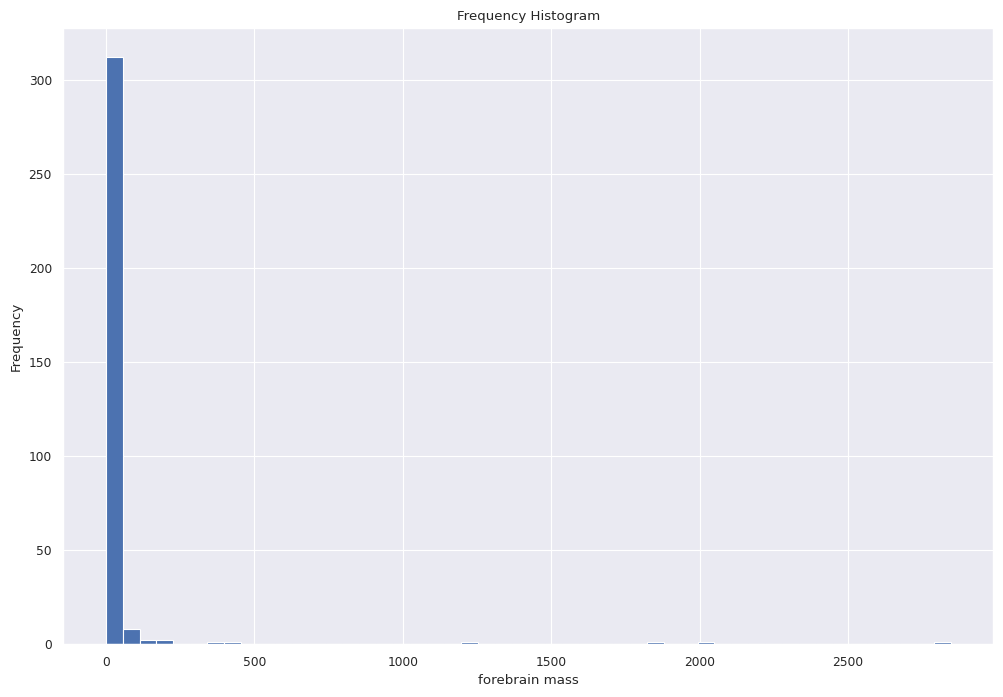

In [17]:
plt.hist(X00_forebrain_mass, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='forebrain mass',ylabel='Frequency')
plt.show()

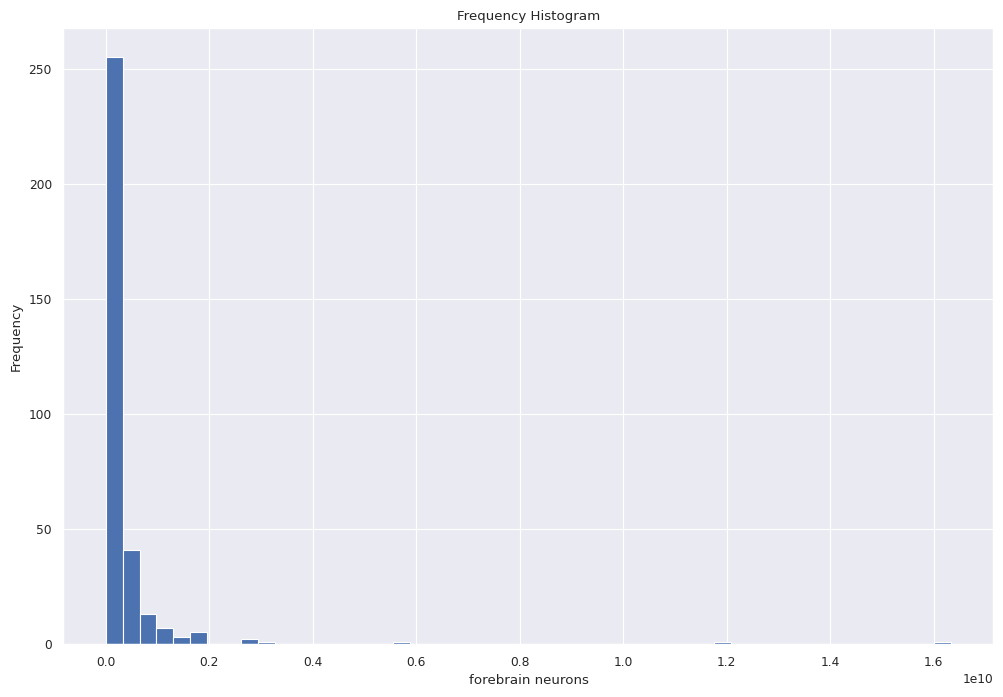

In [18]:
plt.hist(Y00_forebrain_neurons, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='forebrain neurons' ,ylabel='Frequency')
plt.show()

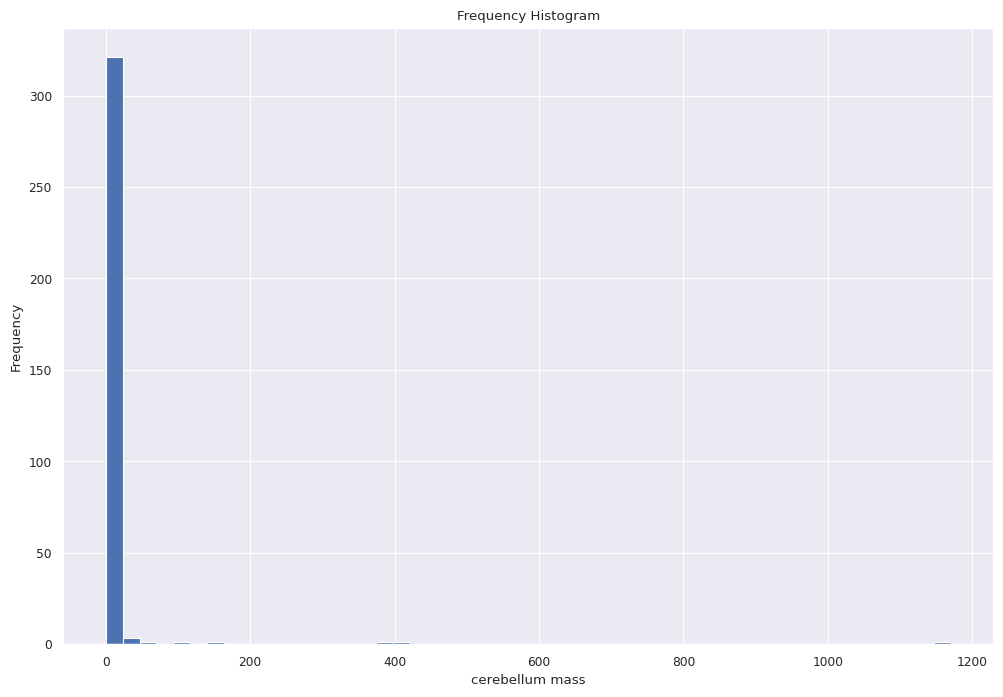

In [19]:
plt.hist(X01_cerebellum_mass, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='cerebellum mass',ylabel='Frequency')
plt.show()

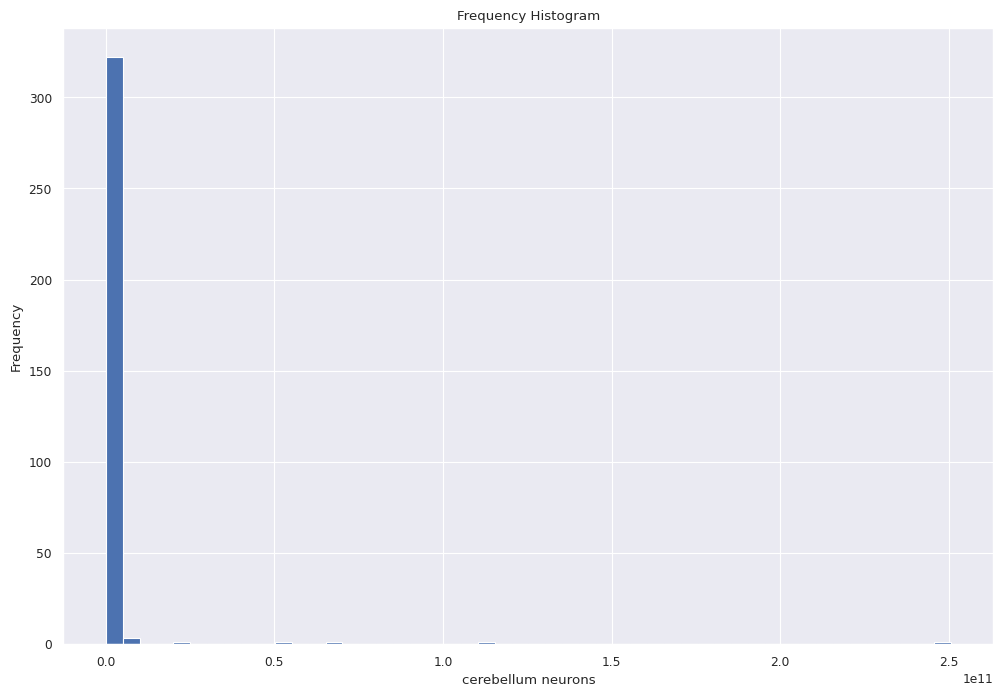

In [20]:
plt.hist(Y01_cerebellum_neurons, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='cerebellum neurons', ylabel='Frequency')
plt.show()

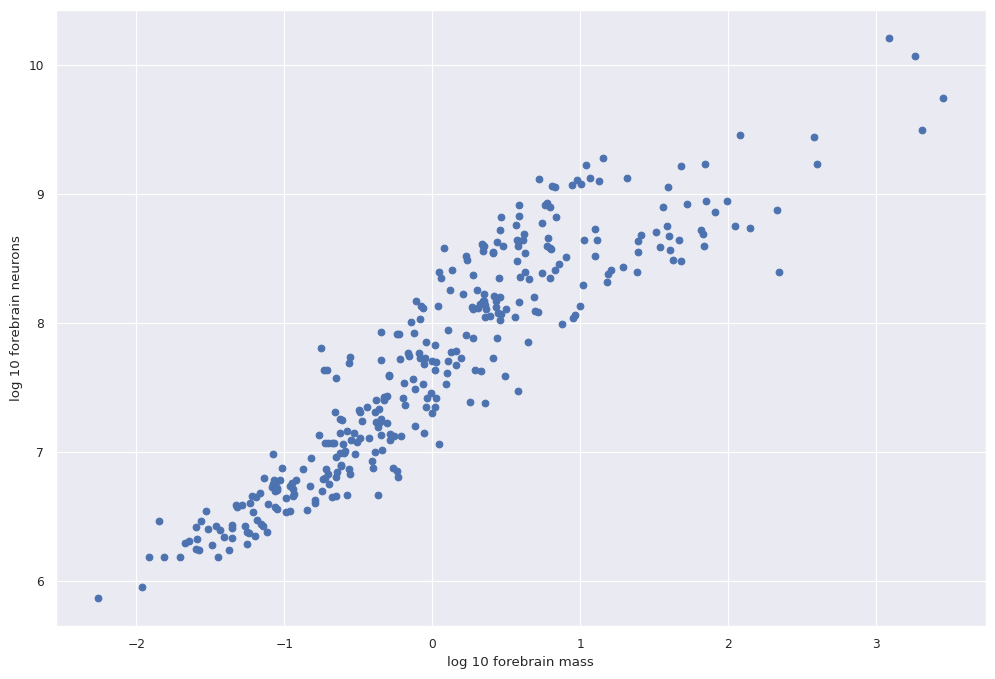

In [21]:
plt.scatter(np.log10(X00_forebrain_mass), np.log10(Y00_forebrain_neurons))
plt.xlabel('log 10 forebrain mass')
plt.ylabel('log 10 forebrain neurons')
plt.show()

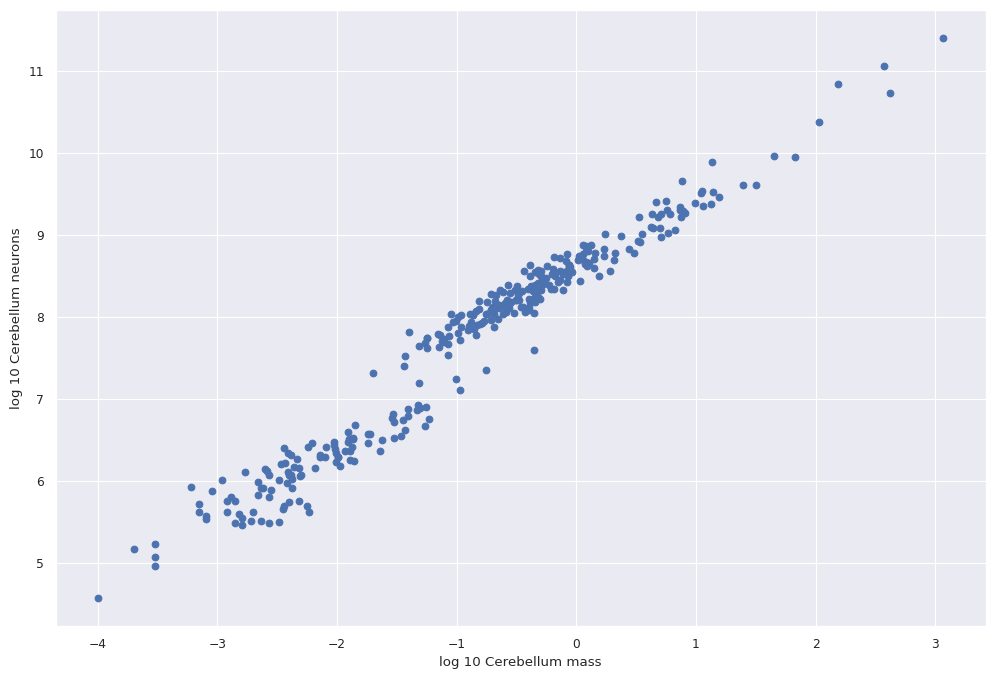

In [22]:
plt.scatter(np.log10(X01_cerebellum_mass), np.log10(Y01_cerebellum_neurons))
plt.xlabel('log 10 Cerebellum mass')
plt.ylabel('log 10 Cerebellum neurons')
plt.show()

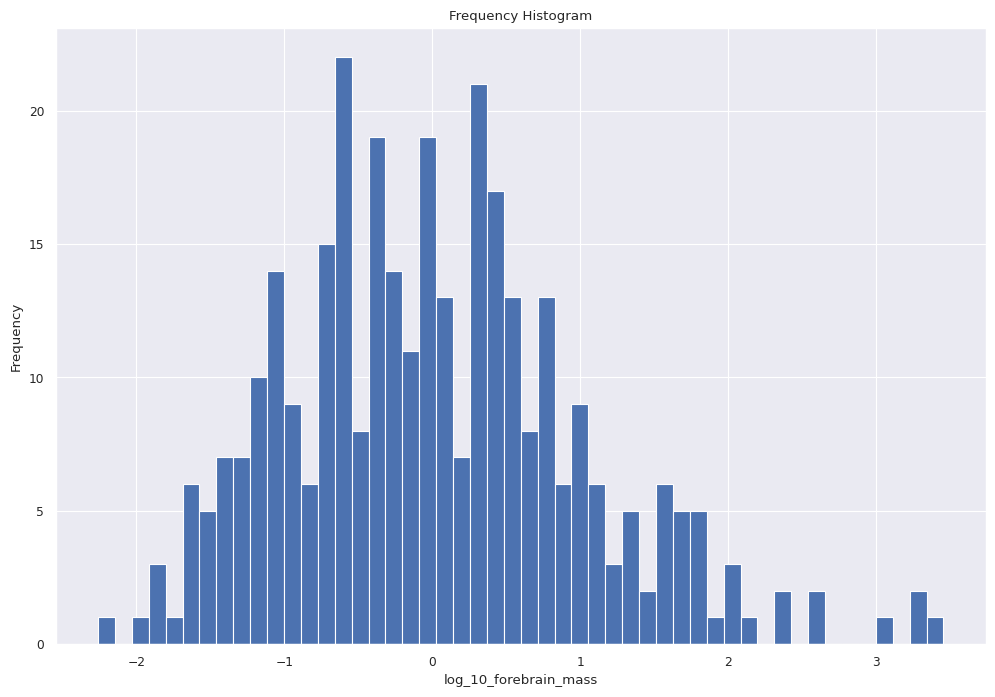

In [23]:
plt.hist(np.log10(X00_forebrain_mass), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_forebrain_mass', ylabel='Frequency')
plt.show()

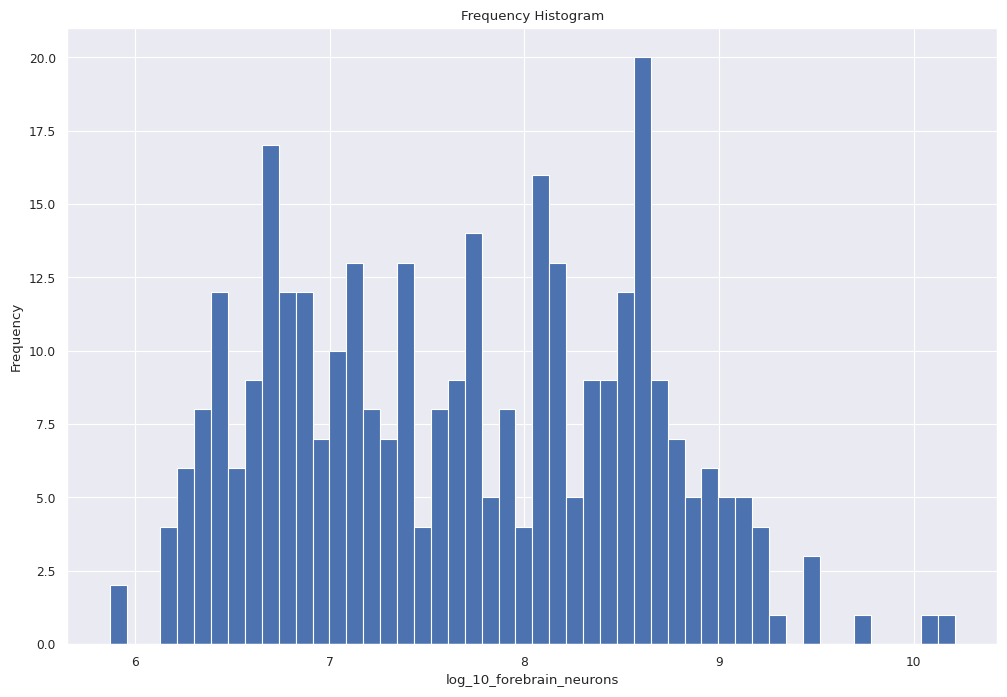

In [24]:
plt.hist(np.log10(Y00_forebrain_neurons), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_forebrain_neurons', ylabel='Frequency')
plt.show()

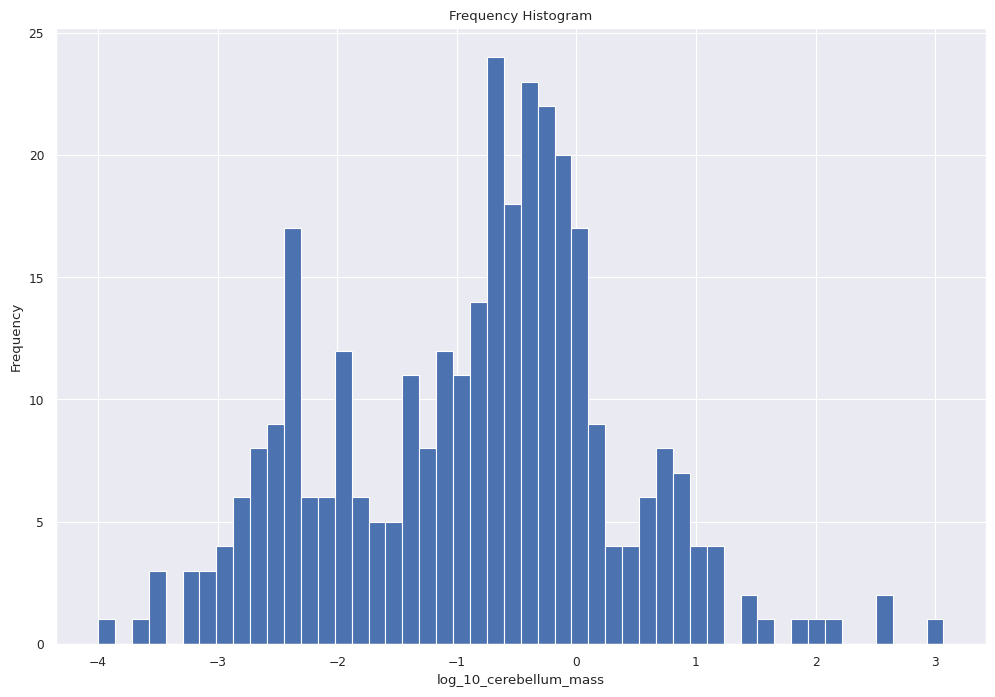

In [25]:
plt.hist(np.log10(X01_cerebellum_mass), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_cerebellum_mass', ylabel='Frequency')
plt.show()

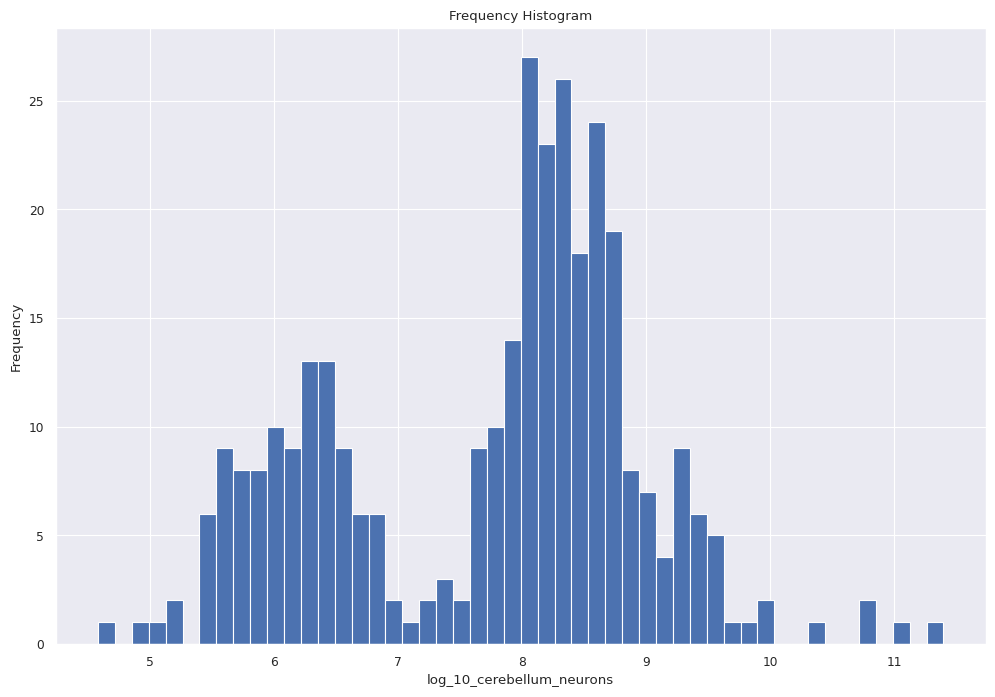

In [26]:
plt.hist(np.log10(Y01_cerebellum_neurons), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_cerebellum_neurons', ylabel='Frequency')
plt.show()

In [27]:
# Saving modified data
Breng.to_csv('/content/All_available_brain_data_with_feature_engineering_20_02_2026.csv')

In [28]:
# Cetacean brain weights and some statistics
m = np.array([2843, 2700, 4900, 3750, 6716, 7085, 5284, 748, 763, 644, 2083, 765, 4305, 2750, 3000, 2700, 1030, 4166, 2893, 2387,
              2720, 2994, 632, 1012, 622, 1103, 1200, 1126, 1148, 886, 510, 1162, 6411, 1440, 1860, 1463, 2149, 2355, 2997, 422,
              468, 6500, 1392, 540, 597, 866, 8028, 295, 221, 4249, 688, 1247, 748, 666, 819, 660, 1542, 1824, 2004])
np.mean(m)

np.float64(2187.762711864407)

In [29]:
np.std(m)

np.float64(1894.8486486581082)

In [30]:
np.median(m)

np.float64(1440.0)

In [31]:
matrix = Breng.corr(numeric_only=True)

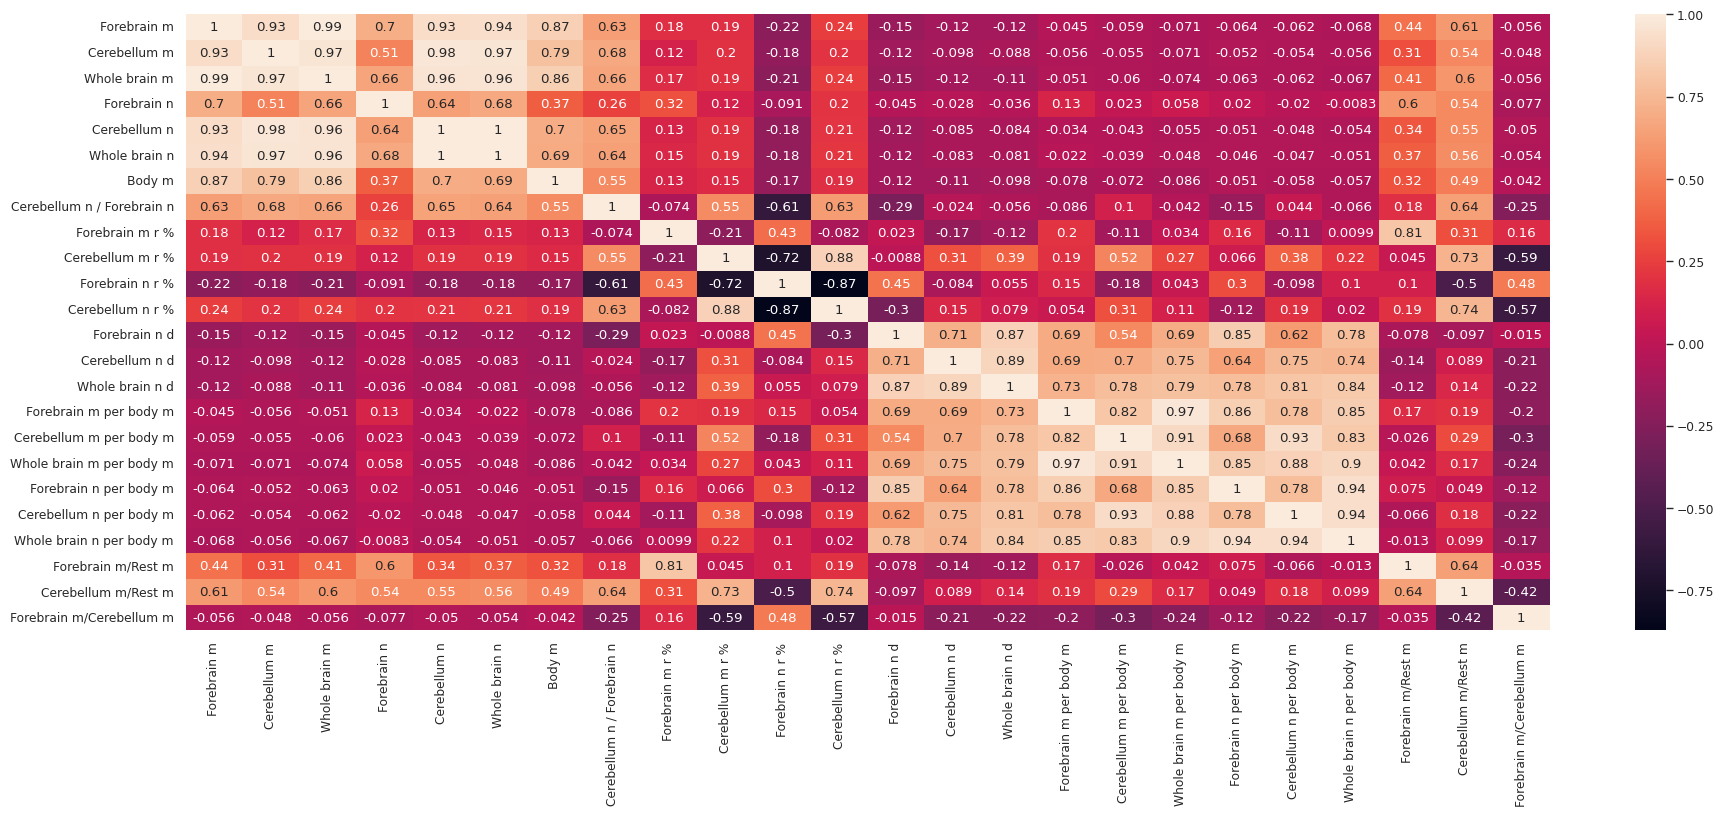

In [32]:
sns.set("paper", rc={"figure.figsize": (22, 8)})
sns.heatmap(matrix, annot=True);

In [33]:
for i in range(1, len(Breng.columns)):
  ratio = max(Breng.iloc[:,i])/min(Breng.iloc[:,i])
  print(Breng.columns[i], 'ratio = ', ratio)

Forebrain m ratio =  517636.36363636365
Cerebellum m ratio =  11710000.0
Whole brain m ratio =  461800.0
Forebrain n ratio =  22081.08108108108
Cerebellum n ratio =  6597368.421052632
Whole brain n ratio =  145138.3399209486
Body m ratio =  7575757.575757576
Cerebellum n / Forebrain n ratio =  2311.968908504051
Forebrain m r % ratio =  3.79766081871345
Cerebellum m r % ratio =  106.13545816733065
Forebrain n r % ratio =  35.15341545352744
Cerebellum n r % ratio =  95.30045497731255
Forebrain n d ratio =  321.6610460504153
Cerebellum n d ratio =  22.359813084112147
Whole brain n d ratio =  32.709499228648355
Forebrain m per body m ratio =  873.7534419885391
Cerebellum m per body m ratio =  14655.172413793105
Whole brain m per body m ratio =  1185.3515625
Forebrain n per body m ratio =  27350.032676776595
Cerebellum n per body m ratio =  327686.9158878505
Whole brain n per body m ratio =  25721.55244023163
Forebrain m/Rest m ratio =  28.439519852262233
Cerebellum m/Rest m ratio =  300.55

# Regression

## Regression with many numerical features, some of which are correlated with each other

In [34]:
X = Breng[["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
          "Cerebellum m per body m", "Whole brain m per body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m"]]
# X = Breng[["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
#          "Cerebellum m per body m", "Whole brain m per body m"]]

Y1 = Breng["Forebrain n"]
Y2 = Breng["Cerebellum n"]
Y3 = Breng["Whole brain n"]

In [35]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [78]:
x_train, x_test, y1_train, y1_test, y2_train, y2_test = train_test_split(X, Y1, Y2, test_size=0.25, random_state=42)

In [79]:
regr_neocortex = RandomForestRegressor(random_state=42)


In [80]:
regr_neocortex.fit(x_train.iloc[:, :-3], y1_train)

RandomForestRegressor(random_state=42)

In [81]:
mse_y1 = mean_squared_error(y1_test, regr_neocortex.predict(x_test.iloc[:, :-3]))
print(mse_y1)

3.13480309565217e+17


In [82]:
r2_y1 = r2_score(y1_test, regr_neocortex.predict(x_test.iloc[:, :-3]))
print(r2_y1)

0.3675733253190815


In [83]:
preds_y1 = regr_neocortex.predict(x_test.iloc[:, :-3])

In [84]:
# cols = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
#          "Cerebellum m per body m", "Whole brain m per body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m"]

cols = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
          "Cerebellum m per body m", "Whole brain m per body m"]

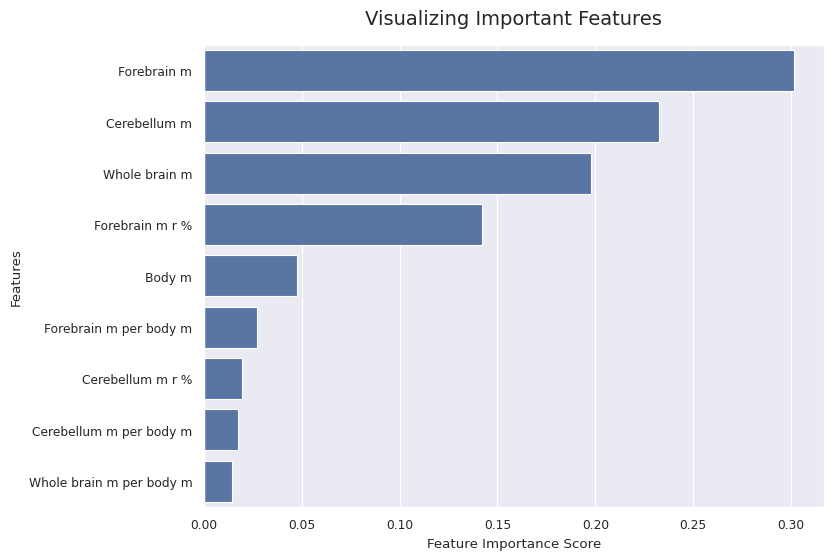

In [85]:
fig01 = plt.figure(figsize=(8, 6))

feature_imp = pd.Series(regr_neocortex.feature_importances_, index=cols).sort_values(ascending=False)

sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title("Visualizing Important Features", pad=15, size=14)
plt.savefig('Barplot.png')

In [86]:
regr_cerebellum = RandomForestRegressor(random_state=42)

In [87]:
regr_cerebellum.fit(x_train.iloc[:, :-3], y2_train)

RandomForestRegressor(random_state=42)

In [88]:
mse_y2 = mean_squared_error(y2_test, regr_cerebellum.predict(x_test.iloc[:, :-3]))
print(mse_y2)

3.0388822709731754e+20


In [89]:
r2_y2 = r2_score(y2_test, regr_cerebellum.predict(x_test.iloc[:, :-3]))
print(r2_y2)
preds_y2 = regr_cerebellum.predict(x_test.iloc[:, :-3])

0.5931955500646297


In [90]:
if 327 in y2_test.index:
    idx_to_drop = y2_test.index.get_loc(327)
    preds_y2 = regr_cerebellum.predict(x_test.iloc[:, :-3])
    y2_test_without_elephant = y2_test.drop(327)
    preds_y2_without_elephant = np.delete(preds_y2, idx_to_drop)

else:
    y2_test_without_elephant = y2_test.copy()
    preds_y2_without_elephant = regr_cerebellum.predict(x_test.iloc[:, :-3])

In [91]:
mse_2_y2 = mean_squared_error(y2_test_without_elephant, preds_y2_without_elephant)
r2_2_y2 = r2_score(y2_test_without_elephant, preds_y2_without_elephant)
print(f"  [Cerebellum n]  MSE = {mse_2_y2:.4e} | R2 = {r2_2_y2:.4f}")

  [Cerebellum n]  MSE = 3.3390e+17 | R2 = 0.7101


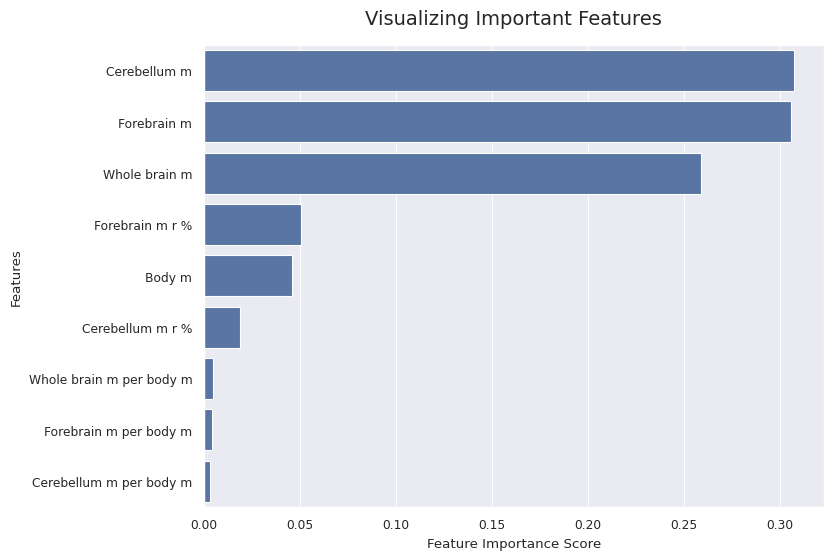

In [92]:
fig01 = plt.figure(figsize=(8, 6))

feature_imp = pd.Series(regr_cerebellum.feature_importances_, index=cols).sort_values(ascending=False)

sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title("Visualizing Important Features", pad=15, size=14)
plt.savefig('Barplot.png')

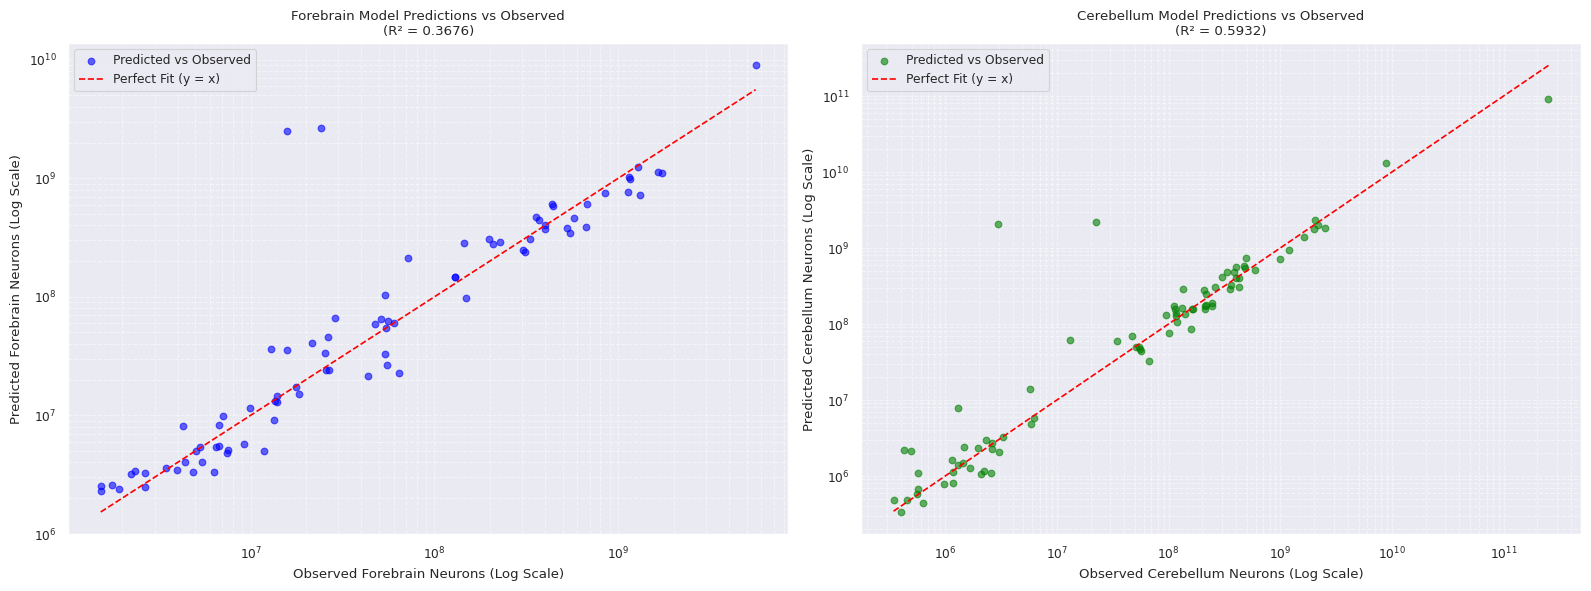

In [93]:
import matplotlib.pyplot as plt
import numpy as np

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Forebrain Plot
axes[0].scatter(y1_test, preds_y1, color='blue', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y1 = np.linspace(min(y1_test), max(y1_test), 100)
axes[0].plot(ideal_y1, ideal_y1, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Observed Forebrain Neurons (Log Scale)')
axes[0].set_ylabel('Predicted Forebrain Neurons (Log Scale)')
axes[0].set_title(f'Forebrain Model Predictions vs Observed\n(R² = {r2_y1:.4f})')
axes[0].legend()
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# 2. Cerebellum Plot
axes[1].scatter(y2_test, preds_y2, color='green', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y2 = np.linspace(min(y2_test), max(y2_test), 100)
axes[1].plot(ideal_y2, ideal_y2, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Observed Cerebellum Neurons (Log Scale)')
axes[1].set_ylabel('Predicted Cerebellum Neurons (Log Scale)')
axes[1].set_title(f'Cerebellum Model Predictions vs Observed\n(R² = {r2_y2:.4f})')
axes[1].legend()
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Regression with each individual feature

In [94]:
for i in range(x_train.shape[1]-2):
    train_feature = x_train.iloc[:,i]
    test_feature = x_test.iloc[:,i]
    regr_neocortex_one = RandomForestRegressor(random_state=42)
    regr_neocortex_one.fit(train_feature.values.reshape(-1,1), y1_train)
    print(x_train.columns[i], 'MSE = ', mean_squared_error(y1_test, regr_neocortex_one.predict(test_feature.values.reshape(-1,1))))
    print(x_train.columns[i], 'r2 = ', r2_score(y1_test, regr_neocortex_one.predict(test_feature.values.reshape(-1,1))))

Forebrain m MSE =  1.1395178993786507e+17
Forebrain m r2 =  0.7701094793344595
Cerebellum m MSE =  1.4245187001127222e+17
Cerebellum m r2 =  0.712612372438133
Whole brain m MSE =  1.17495988806241e+17
Whole brain m r2 =  0.7629592825395041
Body m MSE =  2.8107599370194627e+17
Body m r2 =  0.43294698070158966
Forebrain m r % MSE =  4.1552497788832584e+18
Forebrain m r % r2 =  -7.38295331458785
Cerebellum m r % MSE =  7.74141051832663e+17
Cerebellum m r % r2 =  -0.5617805527356892
Forebrain m per body m MSE =  2.2731311161549558e+18
Forebrain m per body m r2 =  -3.5858980900506117
Cerebellum m per body m MSE =  6.826910508498787e+17
Cerebellum m per body m r2 =  -0.3772859664526653
Whole brain m per body m MSE =  6.295718062845933e+17
Whole brain m per body m r2 =  -0.2701212541025362
Forebrain m/Rest m MSE =  2.368336319876542e+18
Forebrain m/Rest m r2 =  -3.7779685600762134


In [95]:
for i in range(x_train.shape[1]-2):
    train_feature = x_train.iloc[:,i]
    test_feature = x_test.iloc[:,i]
    regr_cerebellum_one = RandomForestRegressor(random_state=42)
    regr_cerebellum_one.fit(train_feature.values.reshape(-1,1), y2_train)
    print(x_train.columns[i], 'MSE = ', mean_squared_error(y2_test, regr_cerebellum_one.predict(test_feature.values.reshape(-1,1))))
    print(x_train.columns[i], 'r2 = ', r2_score(y2_test, regr_cerebellum_one.predict(test_feature.values.reshape(-1,1))))

    preds_y2 = regr_cerebellum_one.predict(test_feature.values.reshape(-1,1))

    if 327 in y2_test.index:
        idx_to_drop = y2_test.index.get_loc(327)
        y2_test_without_elephant = y2_test.drop(327)
        preds_y2_without_elephant = np.delete(preds_y2, idx_to_drop)

    else:
        y2_test_without_elephant = y2_test.copy()
        preds_y2_without_elephant = preds_y2.copy()

    mse_2_y2 = mean_squared_error(y2_test_without_elephant, preds_y2_without_elephant)
    r2_2_y2 = r2_score(y2_test_without_elephant, preds_y2_without_elephant)

    print(x_train.columns[i], f'MSE without elephant = , {mse_2_y2:.4e}')
    print(x_train.columns[i], f'r2 without elephant = , {r2_2_y2:.4f}')

Forebrain m MSE =  3.893396743476555e+20
Forebrain m r2 =  0.47880471193675833
Forebrain m MSE without elephant = , 8.2219e+17
Forebrain m r2 without elephant = , 0.2862
Cerebellum m MSE =  3.885576985025144e+20
Cerebellum m r2 =  0.4798515154163927
Cerebellum m MSE without elephant = , 3.0680e+16
Cerebellum m r2 without elephant = , 0.9734
Whole brain m MSE =  3.893278661470162e+20
Whole brain m r2 =  0.47882051915841906
Whole brain m MSE without elephant = , 8.1024e+17
Whole brain m r2 without elephant = , 0.2966
Body m MSE =  3.16477010163922e+20
Body m r2 =  0.576343390243625
Body m MSE without elephant = , 2.8271e+17
Body m r2 without elephant = , 0.7546
Forebrain m r % MSE =  8.543589193518286e+20
Forebrain m r % r2 =  -0.14370014776188067
Forebrain m r % MSE without elephant = , 9.8691e+19
Forebrain m r % r2 without elephant = , -84.6746
Cerebellum m r % MSE =  8.037043616298585e+20
Cerebellum m r % r2 =  -0.07589067818276973
Cerebellum m r % MSE without elephant = , 4.8779e+19


## Pairing 1 most intuitively important feature with each of others

In [96]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [97]:
cat_cols = []

In [99]:
# 1. Pairwise combinations with 'Forebrain m' (excluding 'Forebrain m' itself)
forebrain_others = [col for col in x_train.columns if col != 'Forebrain m']

print("--- Pairwise combinations with 'Forebrain m' ---\n")
for col_name in forebrain_others:
    features_to_use = ['Forebrain m', col_name]

    # Prepare train and test subsets
    train_subset = x_train[features_to_use]
    test_subset = x_test[features_to_use]

    # Determine transformer requirements dynamically
    step_cat_cols = [c for c in [col_name] if c in cat_cols]

    if step_cat_cols:
        OHE_step = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        transformer = ColumnTransformer([('cat_cols', OHE_step, step_cat_cols)], remainder='passthrough')
    else:
        transformer = 'passthrough'

    pipe = Pipeline([
        ("preprocessing", transformer),
        ("classifier", RandomForestRegressor(random_state=42))
    ])

    # Evaluate for Forebrain n (y1)
    pipe.fit(train_subset, y1_train)
    preds_y1 = pipe.predict(test_subset)
    mse_y1 = mean_squared_error(y1_test, preds_y1)
    r2_y1 = r2_score(y1_test, preds_y1)

    print(f"Features: {features_to_use}")
    print(f"  [Forebrain n]   MSE = {mse_y1:.4e} | R2 = {r2_y1:.4f}")
    print("-" * 50)

print("\n" + "="*60 + "\n")

# 2. Pairwise combinations with 'Cerebellum m' (excluding 'Cerebellum m' itself)
cerebellum_others = [col for col in x_train.columns if col != 'Cerebellum m']

print("--- Pairwise combinations with 'Cerebellum m' ---\n")
for col_name in cerebellum_others:
    features_to_use_cerebellum = ['Cerebellum m', col_name]

    # Prepare train and test subsets
    train_subset_cerebellum = x_train[features_to_use_cerebellum]
    test_subset_cerebellum = x_test[features_to_use_cerebellum]

    # Determine transformer requirements dynamically
    step_cat_cols = [c for c in [col_name] if c in cat_cols]

    if step_cat_cols:
        OHE_step = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        transformer = ColumnTransformer([('cat_cols', OHE_step, step_cat_cols)], remainder='passthrough')
    else:
        transformer = 'passthrough'

    pipe = Pipeline([
        ("preprocessing", transformer),
        ("classifier", RandomForestRegressor(random_state=42))
    ])

    # Evaluate for Cerebellum n (y2)
    pipe.fit(train_subset_cerebellum, y2_train)
    preds_y2 = pipe.predict(test_subset_cerebellum)
    mse_y2 = mean_squared_error(y2_test, preds_y2)
    r2_y2 = r2_score(y2_test, preds_y2)

    print(f"Features: {features_to_use_cerebellum}")
    print(f"  [Cerebellum n]   MSE = {mse_y2:.4e} | R2 = {r2_y2:.4f}")
 #   print("-" * 50)

    if 327 in y2_test.index:
        idx_to_drop = y2_test.index.get_loc(327)
        y2_test_without_elephant = y2_test.drop(327)
        preds_y2_without_elephant = np.delete(preds_y2, idx_to_drop)

    else:
        y2_test_without_elephant = y2_test.copy()
        preds_y2_without_elephant = preds_y2.copy()

    mse_2_y2 = mean_squared_error(y2_test_without_elephant, preds_y2_without_elephant)
    r2_2_y2 = r2_score(y2_test_without_elephant, preds_y2_without_elephant)

#    print(f"Features without elephant: {features_to_use_cerebellum}")
    print('\nScores when elephants are excluded from the test set')
    print(f"  [Cerebellum n]  MSE = {mse_2_y2:.4e} | R2 = {r2_2_y2:.4f}")
    print("-" * 50)


--- Pairwise combinations with 'Forebrain m' ---

Features: ['Forebrain m', 'Cerebellum m']
  [Forebrain n]   MSE = 6.7856e+16 | R2 = 0.8631
--------------------------------------------------
Features: ['Forebrain m', 'Whole brain m']
  [Forebrain n]   MSE = 9.9295e+16 | R2 = 0.7997
--------------------------------------------------
Features: ['Forebrain m', 'Body m']
  [Forebrain n]   MSE = 1.4245e+17 | R2 = 0.7126
--------------------------------------------------
Features: ['Forebrain m', 'Forebrain m r %']
  [Forebrain n]   MSE = 2.5188e+17 | R2 = 0.4918
--------------------------------------------------
Features: ['Forebrain m', 'Cerebellum m r %']
  [Forebrain n]   MSE = 6.5781e+16 | R2 = 0.8673
--------------------------------------------------
Features: ['Forebrain m', 'Forebrain m per body m']
  [Forebrain n]   MSE = 1.7760e+17 | R2 = 0.6417
--------------------------------------------------
Features: ['Forebrain m', 'Cerebellum m per body m']
  [Forebrain n]   MSE = 1.7446e+1

## Using best performing features  

In [104]:
# Features for Forebrain n prediction
features_y1 = ['Forebrain m', 'Cerebellum m r %']
train_subset_y1 = x_train[features_y1]
test_subset_y1 = x_test[features_y1]

# Features for Cerebellum n prediction
features_y2 = ['Cerebellum m', 'Cerebellum m/Rest m']
train_subset_y2 = x_train[features_y2]
test_subset_y2 = x_test[features_y2]

# Transformers
OHE_final = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
transformer = ColumnTransformer([
    ('cat_cols', OHE_final, [])
], remainder='passthrough')

pipe_y1 = Pipeline([
    ("preprocessing", transformer),
    ("classifier", RandomForestRegressor(random_state=42))
])

pipe_y2 = Pipeline([
    ("preprocessing", transformer),
    ("classifier", RandomForestRegressor(random_state=42))
])

# Evaluate for Forebrain n (y1)
pipe_y1.fit(train_subset_y1, y1_train)
preds_y1 = pipe_y1.predict(test_subset_y1)
mse_y1 = mean_squared_error(y1_test, preds_y1)
r2_y1 = r2_score(y1_test, preds_y1)

# Evaluate for Cerebellum n (y2) using Cerebellum m
pipe_y2.fit(train_subset_y2, y2_train)
preds_y2 = pipe_y2.predict(test_subset_y2)
mse_y2 = mean_squared_error(y2_test, preds_y2)
r2_y2 = r2_score(y2_test, preds_y2)

print(f"Forebrain model features: {features_y1}")
print(f"  [Forebrain n]   MSE = {mse_y1:.4e} | R2 = {r2_y1:.4f}")
print(f"\nCerebellum model features: {features_y2}")
print(f"  [Cerebellum n]  MSE = {mse_y2:.4e} | R2 = {r2_y2:.4f}")

Forebrain model features: ['Forebrain m', 'Cerebellum m r %']
  [Forebrain n]   MSE = 6.5781e+16 | R2 = 0.8673

Cerebellum model features: ['Cerebellum m', 'Cerebellum m/Rest m']
  [Cerebellum n]  MSE = 3.8839e+20 | R2 = 0.4801


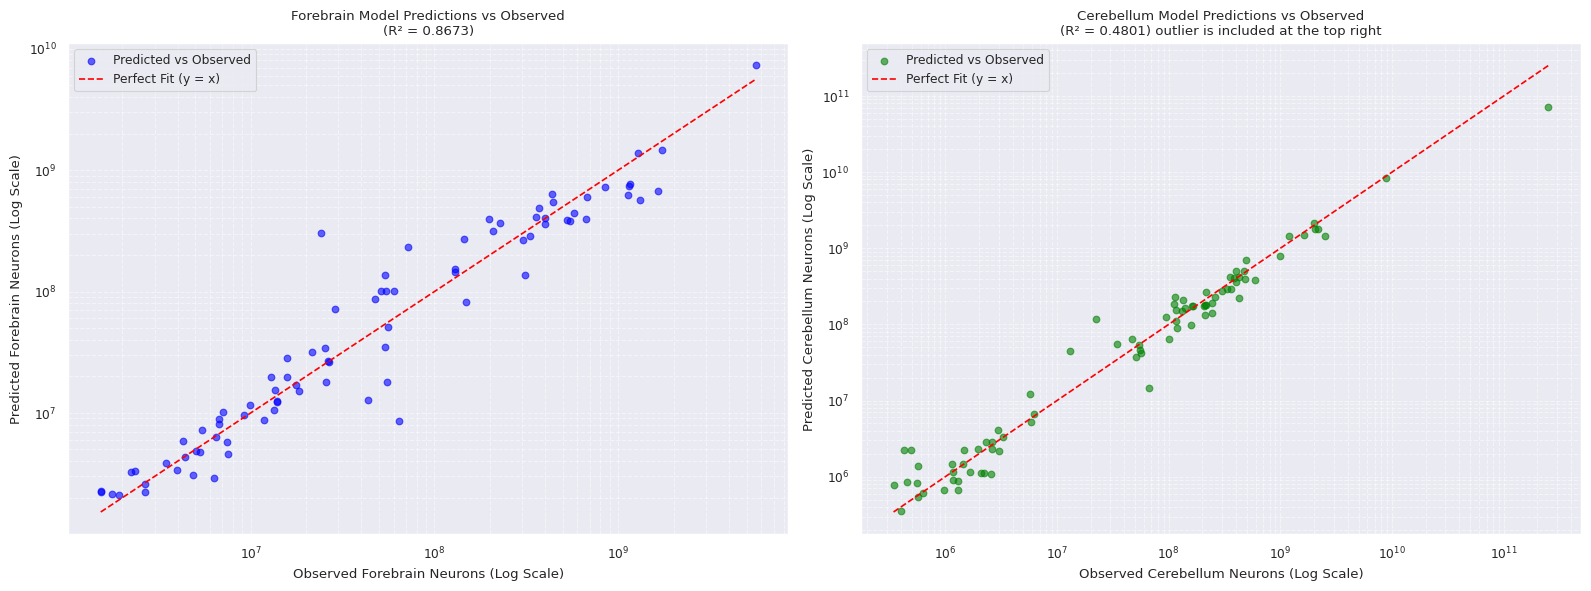

In [109]:
import matplotlib.pyplot as plt
import numpy as np

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Forebrain Plot
axes[0].scatter(y1_test, preds_y1, color='blue', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y1 = np.linspace(min(y1_test), max(y1_test), 100)
axes[0].plot(ideal_y1, ideal_y1, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Observed Forebrain Neurons (Log Scale)')
axes[0].set_ylabel('Predicted Forebrain Neurons (Log Scale)')
axes[0].set_title(f'Forebrain Model Predictions vs Observed\n(R² = {r2_y1:.4f})')
axes[0].legend()
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# 2. Cerebellum Plot
axes[1].scatter(y2_test, preds_y2, color='green', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y2 = np.linspace(min(y2_test), max(y2_test), 100)
axes[1].plot(ideal_y2, ideal_y2, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Observed Cerebellum Neurons (Log Scale)')
axes[1].set_ylabel('Predicted Cerebellum Neurons (Log Scale)')
axes[1].set_title(f'Cerebellum Model Predictions vs Observed\n(R² = {r2_y2:.4f}) outlier is included at the top right')
axes[1].legend()
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [110]:
import pandas as pd
import numpy as np

# Calculate absolute differences for Forebrain
abs_diff_y1 = abs(y1_test - preds_y1)
forebrain_comparison = pd.DataFrame({
    'Observed Forebrain': y1_test,
    'Predicted Forebrain': preds_y1,
    'Absolute Difference': abs_diff_y1
})

# Calculate absolute differences for Cerebellum
abs_diff_y2 = abs(y2_test - preds_y2)
cerebellum_comparison = pd.DataFrame({
    'Observed Cerebellum': y2_test,
    'Predicted Cerebellum': preds_y2,
    'Absolute Difference': abs_diff_y2
})

# Find the positional index of label 90 to delete from the numpy array correctly
if 327 in y2_test.index:
    idx_to_drop = y2_test.index.get_loc(327)
    y2_test_without_elephant = y2_test.drop(327)
    preds_y2_without_elephant = np.delete(preds_y2, idx_to_drop)

    abs_diff2_y2 = abs(y2_test_without_elephant - preds_y2_without_elephant)
    cerebellum_comparison_2 = pd.DataFrame({
        'Observed Cerebellum': y2_test_without_elephant,
        'Predicted Cerebellum': preds_y2_without_elephant,
        'Absolute Difference': abs_diff2_y2
    })
else:
    cerebellum_comparison_2 = cerebellum_comparison.copy()

print("=== Forebrain: Observed vs Predicted (Sample) ===")
display(forebrain_comparison.head(10))
print("\nForebrain Absolute Difference Statistics:")
display(forebrain_comparison['Absolute Difference'].describe())

print("\n=== Cerebellum: Observed vs Predicted (Sample) ===")
display(cerebellum_comparison.head(10))
print("\nCerebellum Absolute Difference Statistics:")
display(cerebellum_comparison['Absolute Difference'].describe())

print("\n=== Cerebellum without elephants: Observed vs Predicted (Sample) ===")
display(cerebellum_comparison_2.head(10))
print("\nCerebellum without elephants Absolute Difference Statistics:")
display(cerebellum_comparison_2['Absolute Difference'].describe())

=== Forebrain: Observed vs Predicted (Sample) ===


,Observed Forebrain,Predicted Forebrain,Absolute Difference
9,1.920000e+06,2110390.0,190390.0
164,4.733100e+07,86717430.0,39386430.0
139,2.544000e+07,34419290.0,8979290.0
46,4.389000e+06,4331650.0,57350.0
94,9.884000e+06,11664900.0,1780900.0
101,1.180100e+07,8747010.0,3053990.0
84,7.484000e+06,4604010.0,2879990.0
311,1.153000e+09,767403610.0,385596390.0
316,1.308000e+09,563782720.0,744217280.0
219,1.455610e+08,271647600.0,126086600.0



Forebrain Absolute Difference Statistics:


,Absolute Difference
count,8.300000e+01
mean,1.008481e+08
std,2.372522e+08
min,5.735000e+04
25%,1.454065e+06
50%,1.226466e+07
75%,1.046024e+08
max,1.683188e+09



=== Cerebellum: Observed vs Predicted (Sample) ===


,Observed Cerebellum,Predicted Cerebellum,Absolute Difference
9,980000.0,673720.0,306280.0
164,210346000.0,177672940.0,32673060.0
139,94820000.0,125668220.0,30848220.0
46,2336000.0,2834920.0,498920.0
94,1461000.0,2259920.0,798920.0
101,570000.0,1379110.0,809110.0
84,1659000.0,1157190.0,501810.0
311,334017000.0,289317160.0,44699840.0
316,299621000.0,270456300.0,29164700.0
219,403410000.0,354904990.0,48505010.0


... (2 outputs left out)


=== Cerebellum without elephants: Observed vs Predicted (Sample) ===


,Observed Cerebellum,Predicted Cerebellum,Absolute Difference
9,980000.0,673720.0,306280.0
164,210346000.0,177672940.0,32673060.0
139,94820000.0,125668220.0,30848220.0
46,2336000.0,2834920.0,498920.0
94,1461000.0,2259920.0,798920.0
101,570000.0,1379110.0,809110.0
84,1659000.0,1157190.0,501810.0
311,334017000.0,289317160.0,44699840.0
316,299621000.0,270456300.0,29164700.0
219,403410000.0,354904990.0,48505010.0



Cerebellum without elephants Absolute Difference Statistics:


,Absolute Difference
count,8.200000e+01
mean,6.443628e+07
std,1.420606e+08
min,1.690000e+03
25%,6.493000e+05
50%,1.797570e+07
75%,6.526940e+07
max,1.062474e+09


In [111]:
mse_2_y2 = mean_squared_error(y2_test_without_elephant, preds_y2_without_elephant)
r2_2_y2 = r2_score(y2_test_without_elephant, preds_y2_without_elephant)
# print(f"\nCerebellum model features without elephant: {features_y2}")
print(f"  [Cerebellum n]  MSE = {mse_2_y2:.4e} | R2 = {r2_2_y2:.4f}")

  [Cerebellum n]  MSE = 2.4087e+16 | R2 = 0.9791
